# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Izra, Rashi, Mustafa"

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


/Users/mustafaali/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


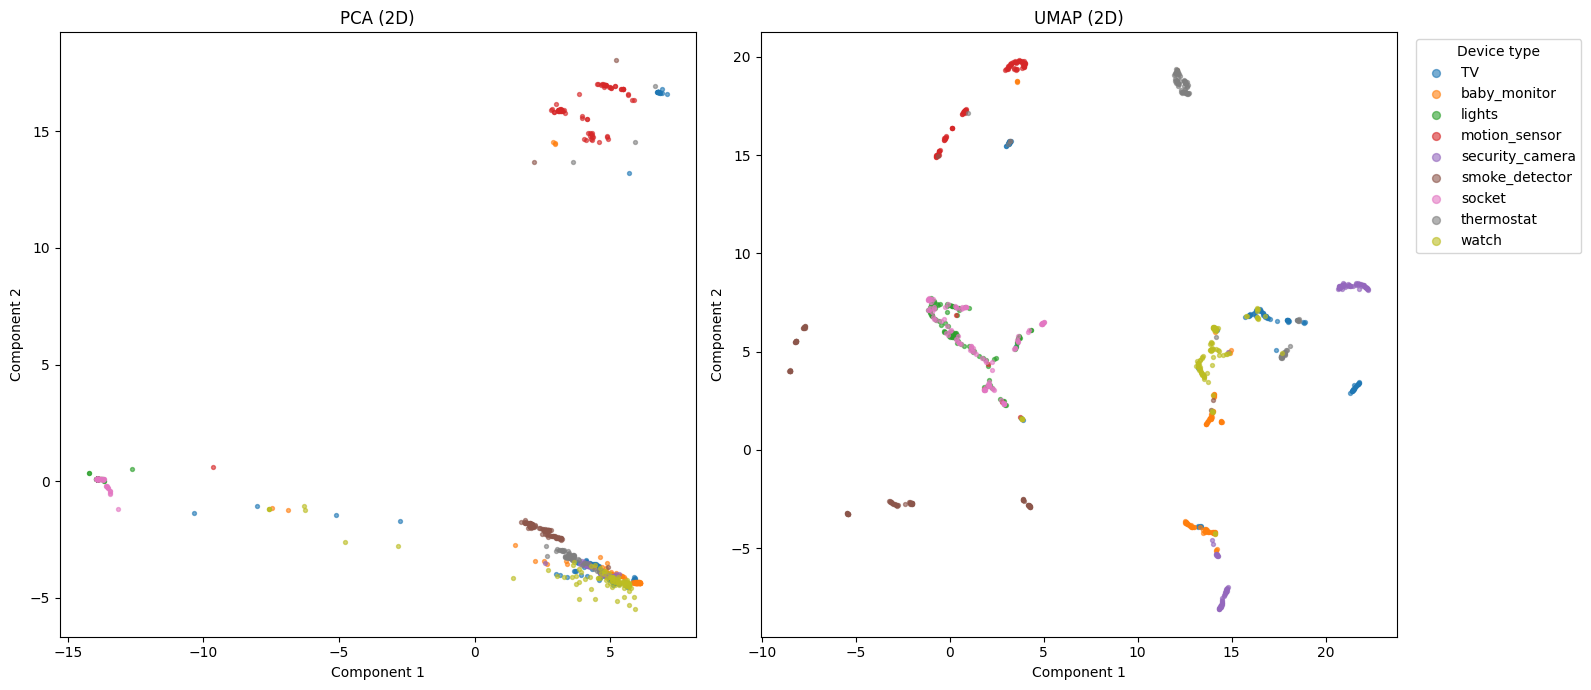

In [5]:
# USE AS MANY CELLS AS NEEDED
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
import umap
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

train = pd.read_csv("iot_devices_train.csv")
reporting = pd.read_csv("iot_devices_reporting.csv")

train_X = train.drop(columns=["device_category"])
train_y = train["device_category"]

reporting_X = reporting.drop(columns=["device_category"])
reporting_y = reporting["device_category"]

label_encoder = LabelEncoder()
label_encoder.fit(train_y)
train_y = label_encoder.transform(train_y)
reporting_y = label_encoder.transform(reporting_y)

pipePCA = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2, random_state=42))])
pipeUMAP = Pipeline([("scaler", StandardScaler()), ("umap", umap.UMAP(n_components=2, random_state=42))])

train_pca_X = pipePCA.fit_transform(train_X)
reporting_pca_X = pipePCA.transform(reporting_X)

train_umap_X = pipeUMAP.fit_transform(train_X)
reporting_umap_X = pipeUMAP.transform(reporting_X)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, emb, title in zip(axes, [train_pca_X, train_umap_X], ["PCA (2D)", "UMAP (2D)"]):
    for code, name in enumerate(label_encoder.classes_):
        mask = train_y == code
        ax.scatter(emb[mask, 0], emb[mask, 1], s=8, alpha=0.6, label=name)
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
axes[1].legend(title="Device type", bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=2)
plt.tight_layout()
plt.show()

The PCA visualization maintains a good global structure and seems to link similar components with each other, but at the cost of making them overlap and some of the groups differences are less defined. The cluster overlap in short. This is contrasted by UMAP which seem to maintain a great local structure where every cluster is much more pronounced and has a clearer line of separation, but at the cost of the global structure taking the backseat.

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

1. Tree-based ensemble methods like Random Forests and Gradient Boosting do not require feature scaling or normalization because they split data based on feature values rather than actual distances. They require encoding to convert categorical variables into numerical ones and should also handle missing values. 

In [6]:
#2 

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from time import time

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gb_params = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2] }

rf_params = {
    "max_depth": [3, 5, 7],
    "max_features": ["sqrt", "log2", None]}

gb_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1)

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1)

start = time()
gb_search.fit(train_X, train_y)
gb_time = (time() - start) / 60

start = time()
rf_search.fit(train_X, train_y)
rf_time = (time() - start) / 60

print("Gradient Boosting best parameters:", gb_search.best_params_)
print("Gradient Boosting CV accuracy:", gb_search.best_score_)

print("Random Forest best parameters:", rf_search.best_params_)
print("Random Forest CV accuracy:", rf_search.best_score_)

Gradient Boosting best parameters: {'learning_rate': 0.1, 'max_depth': 3}
Gradient Boosting CV accuracy: 0.8899999999999999
Random Forest best parameters: {'max_depth': 7, 'max_features': 'sqrt'}
Random Forest CV accuracy: 0.8788888888888889


In [7]:
#3 

from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

gb_pred = gb_search.predict(reporting_X)
rf_pred = rf_search.predict(reporting_X)

print("Gradient Boosting")
print("Accuracy:", accuracy_score(reporting_y, gb_pred))
print("Confusion Matrix:\n", confusion_matrix(reporting_y, gb_pred))
print("Total fitting time (minutes):", gb_time)

print("\nRandom Forest")
print("Accuracy:", accuracy_score(reporting_y, rf_pred))
print("Confusion Matrix:\n", confusion_matrix(reporting_y, rf_pred))
print("Total fitting time (minutes):", rf_time)

gb_recall = recall_score(reporting_y, gb_pred, labels=range(len(label_encoder.classes_)), average=None, zero_division=0)
rf_recall = recall_score(reporting_y, rf_pred, labels=range(len(label_encoder.classes_)), average=None, zero_division=0)

print("\nRecall by device type:")
for device, gb, rf in zip(label_encoder.classes_, gb_recall, rf_recall):
    print(f"{device}: Gradient Boosting = {gb:.3f}, Random Forest = {rf:.3f}")

Gradient Boosting
Accuracy: 0.6788888888888889
Confusion Matrix:
 [[ 78   2   0   0   2   0   0   0  18]
 [ 13  74   0   0   1   0   0  12   0]
 [  0   0  49   0   0   0  51   0   0]
 [ 19   0   0  54   0   0   0   8  19]
 [  0   0   0   4  34   0   0  30  32]
 [  0   0   0   0   0 100   0   0   0]
 [  0   0  22   1   0   0  77   0   0]
 [  6   0   0   0   0   0   2  92   0]
 [ 44   1   0   0   0   0   0   2  53]]
Total fitting time (minutes): 1.083446729183197

Random Forest
Accuracy: 0.6233333333333333
Confusion Matrix:
 [[ 36   4   1   0   1   0   0   0  58]
 [ 13  86   0   0   0   0   0   1   0]
 [  0   0  56   0   0   0  44   0   0]
 [ 24   1   0  65   0   0   0   2   8]
 [  0   0   0  34  34   0   0   0  32]
 [  0   0   0   0   0 100   0   0   0]
 [  0   0  25   0   0   0  75   0   0]
 [ 59   0   0   0   2   0   0  39   0]
 [ 28   0   0   0   0   0   0   2  70]]
Total fitting time (minutes): 0.03342818816502889

Recall by device type:
TV: Gradient Boosting = 0.780, Random Forest 

Random forest achieved a slightly higher accuracy (69.22%) than gradient boosting (67.56%) on the reporting data. Both models classified smoke detectors well, with 100% recall. Additionally, sockets and thermostats also performed relatively well, while watches were harder to classify. The confusion matrices also show that some device types are frequently misclassified as others, suggesting that their features may be similar. 

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`? 

Hist is faster than the regular kind, and it scales better with increased number of samples without slowing down as drastically. It can handle missing values without additional inputs. It can avoid hot encoding within the function itself as it supports them natively. Early stopping is built in and more robust, and you can control depth and leaf node counts instead of just depth.

How does histogram binning make training faster?

Finding the splits is the most expensive part of boosting. In hist, the splits occur not by scanning every single value, but by picking 255 integer bins which halts the problem far before you read every single input value you have to decide the split points for the bins. Binning is done once, and while precision is lost, it normally isn't significant as 255 bins gets most of the diminishing precision increases associated with more bins.

HistGB best parameters: {'learning_rate': 0.2, 'max_depth': 3}
HistGB CV accuracy: 0.8855555555555554
HistGB search time: 0.36 min
Gradient Boosting search time: 1.08 min
HistGB reporting accuracy: 0.6666666666666666


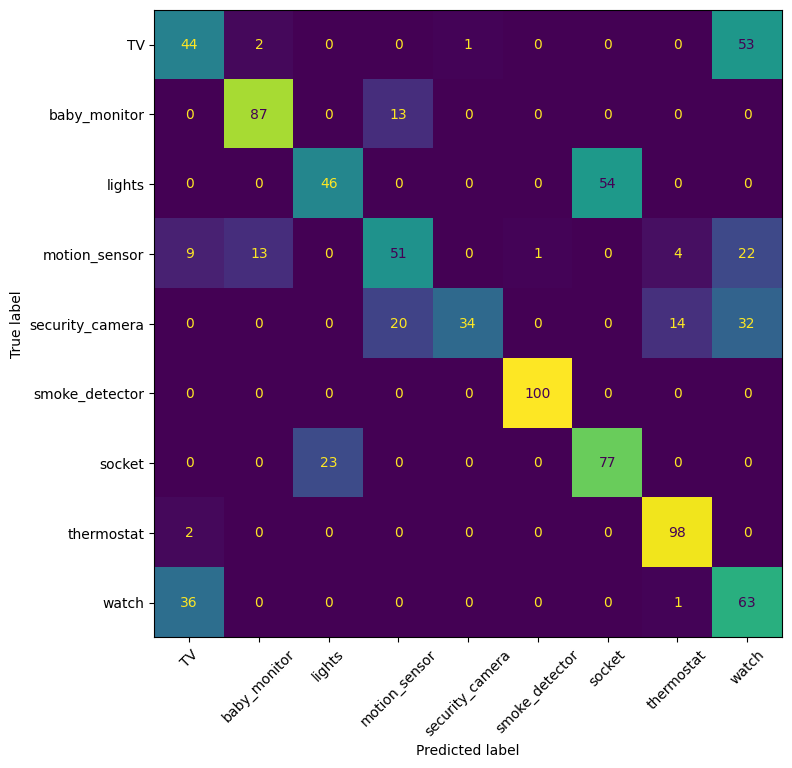

In [8]:
# USE AS MANY CELLS AS NEEDED
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from time import time

hgb_search = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    gb_params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1)

start = time()
hgb_search.fit(train_X, train_y)
hgb_time = (time() - start) / 60

print("HistGB best parameters:", hgb_search.best_params_)
print("HistGB CV accuracy:", hgb_search.best_score_)
print(f"HistGB search time: {hgb_time:.2f} min")
print(f"Gradient Boosting search time: {gb_time:.2f} min")

best_hgb = hgb_search.best_estimator_
pred = best_hgb.predict(reporting_X)
print("HistGB reporting accuracy:", accuracy_score(reporting_y, pred))

cm = confusion_matrix(reporting_y, pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=label_encoder.classes_).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

Computation Time:
HistGradientBoostingClassifier took about 0.76 min and Gradient Boosting took 0.70 min for the hyper parameter tuning.

Predictive performance:
HistGradientBoostingClassifier had 0.6666666666666666 accuracy, and Gradient Boosting had 0.6811111111111111 accuracy.

Trade-offs:

Seemingly against expectations, which might be the case with a dataset with more records, Hist took slightly more time for a slight dip in accuracy, but if we had more cases, ordinarily we'd expect to see HistGradientBoostingClassifier perform a little faster, but the accuracy tells the story we'd expect.

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


For preprocessing steps we normalize and scale because it reduces the effect of a columns magnitude / scale and it also helps speed up the rate at which it converges which reduces computuational time. 

MLP best parameters: {'mlp__hidden_layer_sizes': (64, 64, 64)}
MLP CV accuracy: 0.8433333333333334
MLP reporting accuracy: 0.18
MLP search time: 0.03 min
Confusion Matrix:
 [[10 82  0  0  1  2  0  4  1]
 [ 0 12  0  0 75  0  0  0 13]
 [ 0  0  0  0  0  0 84  0 16]
 [20 35  0  2  8  4  0 29  2]
 [ 2  2  0 32 16  0  0 16 32]
 [ 0 50  0  0  0 50  0  0  0]
 [ 0  0  0  0  0  0 70  0 30]
 [ 0  0  0  0 99  0  0  1  0]
 [ 3 87  0  0  4  0  0  5  1]]

Recall by device type:
TV: 0.100
baby_monitor: 0.120
lights: 0.000
motion_sensor: 0.020
security_camera: 0.160
smoke_detector: 0.500
socket: 0.700
thermostat: 0.010
watch: 0.010


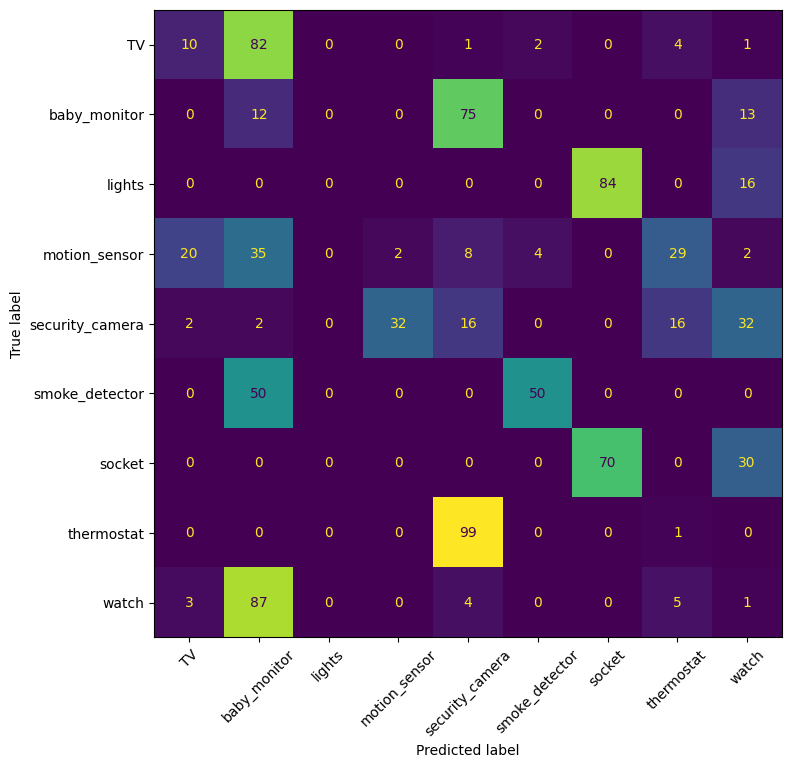

In [10]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, recall_score
import matplotlib.pyplot as plt
from time import time

# scaling is inside the pipeline so it is fit only on each training fold (no leakage)
mlp_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(max_iter=300, early_stopping=True, n_iter_no_change=10, random_state=42)),
])

# 9 combinations: 1, 2, or 3 hidden layers x 32, 64, or 128 units per layer
mlp_params = {
    "mlp__hidden_layer_sizes": [(u,) * l for l in (1, 2, 3) for u in (32, 64, 128)]
}

# same cv object as Parts 2 and 3
mlp_search = GridSearchCV(mlp_pipe, mlp_params, cv=cv, scoring="accuracy", n_jobs=-1)

start = time()
mlp_search.fit(train_X, train_y)
mlp_time = (time() - start) / 60

mlp_pred = mlp_search.predict(reporting_X)

print("MLP best parameters:", mlp_search.best_params_)
print("MLP CV accuracy:", mlp_search.best_score_)
print("MLP reporting accuracy:", accuracy_score(reporting_y, mlp_pred))
print(f"MLP search time: {mlp_time:.2f} min")
print("Confusion Matrix:\n", confusion_matrix(reporting_y, mlp_pred))

mlp_recall = recall_score(reporting_y, mlp_pred, labels=range(len(label_encoder.classes_)), average=None, zero_division=0)
print("\nRecall by device type:")
for device, r in zip(label_encoder.classes_, mlp_recall):
    print(f"{device}: {r:.3f}")

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix(reporting_y, mlp_pred), display_labels=label_encoder.classes_).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

In [11]:
import numpy as np
from sklearn.preprocessing import FunctionTransformer

# diagnose: how extreme do reporting features look after scaling with train stats?
z = StandardScaler().fit(train_X).transform(reporting_X)
print("max |z| on reporting:", np.abs(z).max())
print("features with |z| > 10 on reporting:", (np.abs(z).max(axis=0) > 10).sum(), "of", z.shape[1])

# same MLP grid, but clip scaled values to [-5, 5]
mlp_pipe2 = Pipeline([
    ("scaler", StandardScaler()),
    ("clip", FunctionTransformer(np.clip, kw_args={"a_min": -5, "a_max": 5})),
    ("mlp", MLPClassifier(max_iter=300, early_stopping=True, n_iter_no_change=10, random_state=42)),
])
mlp_search2 = GridSearchCV(mlp_pipe2, mlp_params, cv=cv, scoring="accuracy", n_jobs=-1)
mlp_search2.fit(train_X, train_y)
print("Clipped MLP best params:", mlp_search2.best_params_)
print("Clipped MLP CV accuracy:", mlp_search2.best_score_)
print("Clipped MLP reporting accuracy:", accuracy_score(reporting_y, mlp_search2.predict(reporting_X)))

max |z| on reporting: 2.30584300650885e+18
features with |z| > 10 on reporting: 123 of 297
Clipped MLP best params: {'mlp__hidden_layer_sizes': (128, 128, 128)}
Clipped MLP CV accuracy: 0.8433333333333334
Clipped MLP reporting accuracy: 0.5166666666666667


In [12]:
import pandas as pd

summary = pd.DataFrame({
    "Model": ["Gradient Boosting", "Random Forest", "HistGradientBoosting", "MLP"],
    "Reporting accuracy": [
        accuracy_score(reporting_y, gb_pred),
        accuracy_score(reporting_y, rf_pred),
        accuracy_score(reporting_y, pred),
        accuracy_score(reporting_y, mlp_pred),
    ],
    "Search time (min)": [gb_time, rf_time, hgb_time, mlp_time],
})
print(summary.round(3).to_string(index=False))

               Model  Reporting accuracy  Search time (min)
   Gradient Boosting               0.679              1.083
       Random Forest               0.623              0.033
HistGradientBoosting               0.667              0.365
                 MLP               0.180              0.030


Preprocessing. We standardized the features inside a pipeline so the scaler was only fit on each training fold. Neural networks need this because they are sensitive to feature scale, unlike the tree models in Parts 2 and 3.

Results. The best MLP from the grid search had three hidden layers of 64 units. It reached 84.3% CV accuracy but only 18.0% on the reporting data, which is only a little above the 11.1% you would get from random guessing across 9 classes. Recall was very low for most devices (0.00 for lights, 0.01 for thermostat and watch). The cause is the scaling. Many features are almost constant in the training data, so after standardizing they have a tiny standard deviation, and the same features in the reporting data turned into huge values (the largest |z| was around 2e18, and 123 of 297 features went above 10). Trees only care about the order of values, so they were not affected. After clipping the scaled features to [-5, 5], reporting accuracy rose to 51.7% with CV accuracy unchanged at 84.3%.

Comparison. Even after this fix, the MLP was worse than all three ensemble models on the reporting data (Gradient Boosting 67.9%, HistGradientBoosting 66.7%, Random Forest 62.3%). All the models had similar CV accuracy of roughly 84 to 89%, so there is a gap between the training data and the reporting data in general, but the neural network was hurt the most by it. The MLP search finished in about 0.03 min, far faster than Gradient Boosting (about 1.08 min) and HistGradientBoosting (about 0.37 min), and about the same as Random Forest (about 0.03 min).

Complexity and interpretability. The MLP has the most parameters and needs the most preprocessing decisions (scaling, clipping, architecture, early stopping). Its weights do not tell us which features matter. The tree ensembles are more robust to messy features and are easier to interpret through feature importances, which is a real advantage when you need to explain why a device was classified a certain way. For this dataset the ensemble methods are the better choice.

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

One inefficiency we ran into was that some of our written answers did not match what the notebook actually printed. The Part 2 discussion had the wrong accuracies and named the wrong hardest device, and after packages were updated to get the notebook running, the numbers shifted slightly, which made the Part 3 timing comparison wrong too. We ended up fixing written answers late in the process instead of writing them from the final outputs. In the next lab, we will run the whole notebook top to bottom first and write the discussion from those outputs, with one person checking every written number against the printed results before we push.